In [34]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    ConfusionMatrixDisplay
)
from sklearn.metrics import roc_curve


In [35]:
cancer = load_breast_cancer()

In [36]:
df = pd.DataFrame(
    cancer.data,
    columns=cancer.feature_names
)

In [37]:
# Create target column
# 1 = Malignant (Cancerous)
# 0 = Benign (Non-cancerous)

df['target'] = (cancer.target == 0).astype(int)

In [38]:
# Display first five records

print("First Five Records:")
print(df.head())

# Dataset information

print("\nDataset Information:")
print(df.info())

# Dataset dimensions

print("\nDataset Shape:", df.shape)

# Check missing values

print("\nMissing Values:")
print(df.isnull().sum().sum())

# Check class distribution

print("\nTarget Distribution:")
print(df['target'].value_counts())


First Five Records:
   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2414              0.10520         0.2597   
4           0.13280          0.1980              0.10430         0.1809   

   mean fractal dimension  ...  worst texture  worst perimeter  worst ar

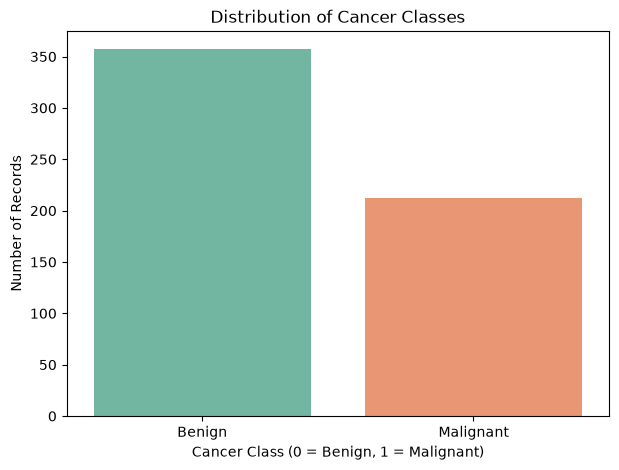

In [39]:
# 1. Class Distribution

plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x='target',
    hue='target',
    palette='Set2',
    legend=False
)

plt.title("Distribution of Cancer Classes")
plt.xlabel("Cancer Class (0 = Benign, 1 = Malignant)")
plt.ylabel("Number of Records")
plt.xticks([0, 1], ['Benign', 'Malignant'])

plt.savefig("screenshots/class_distribution.png")
plt.show()

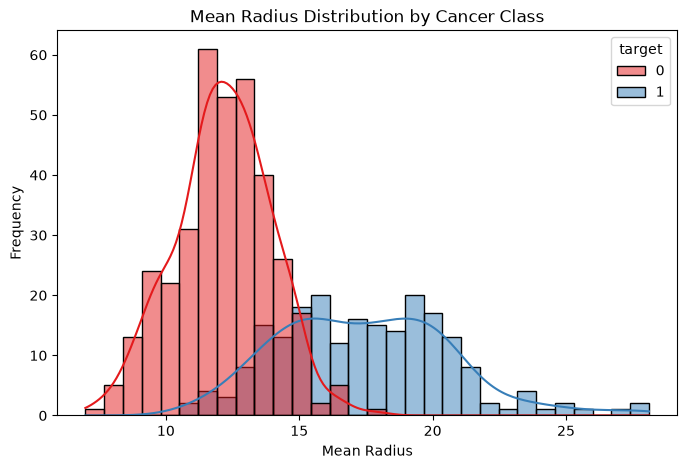

In [40]:
# 2. Tumour Radius Distribution

plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x='mean radius',
    hue='target',
    kde=True,
    bins=30,
    palette='Set1'
)

plt.title("Mean Radius Distribution by Cancer Class")
plt.xlabel("Mean Radius")
plt.ylabel("Frequency")

plt.savefig("screenshots/radius_distribution.png")
plt.show()


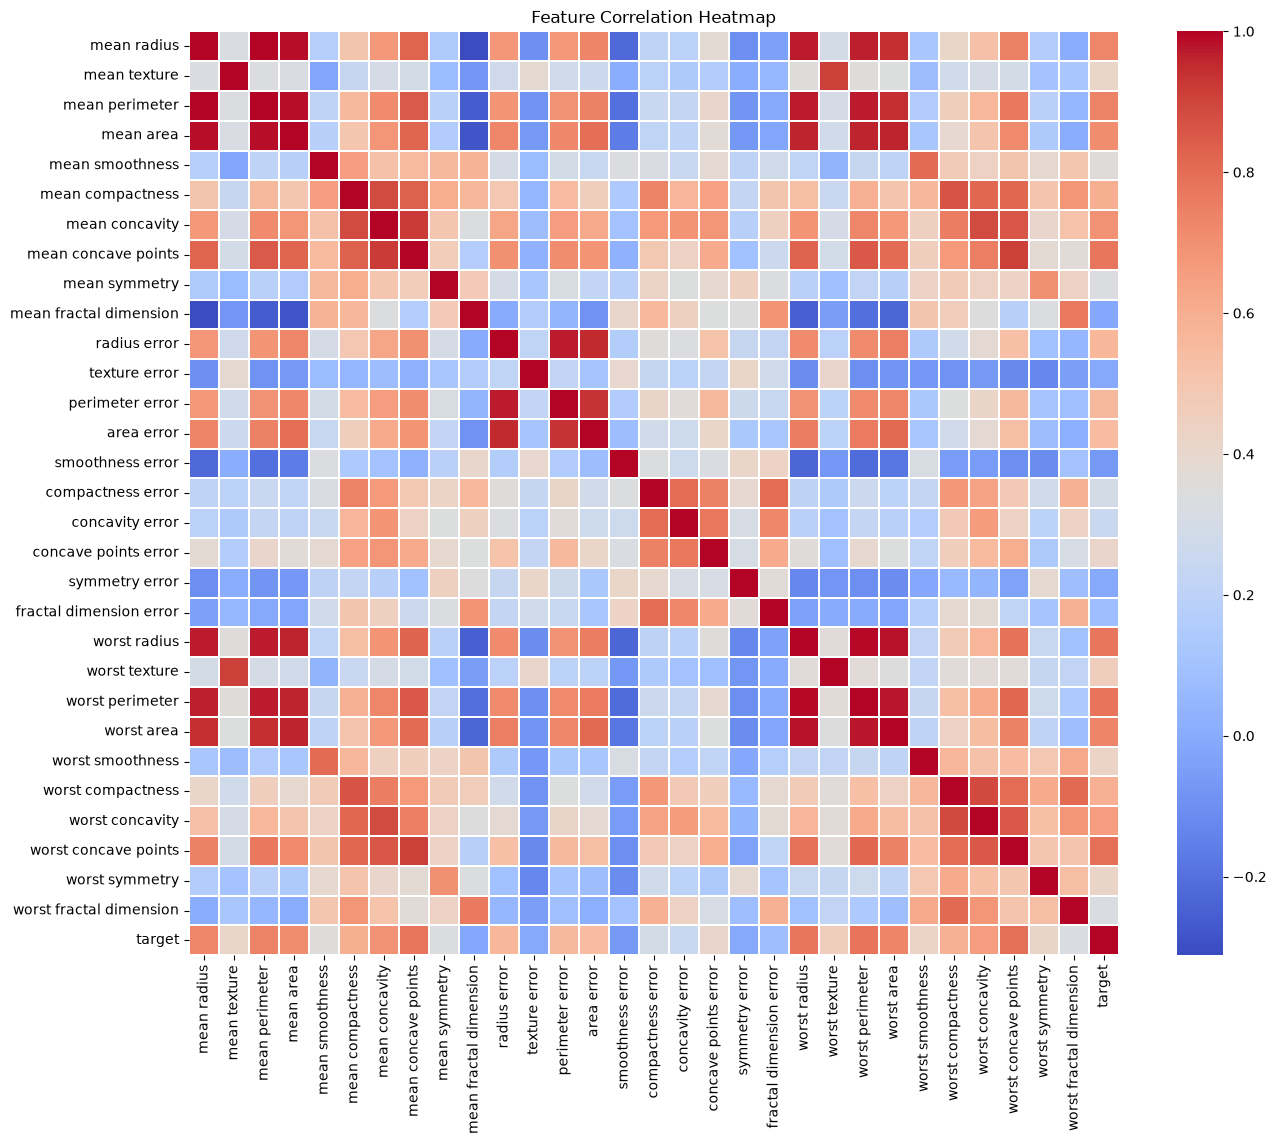

In [41]:
# 3. Correlation Heatmap

plt.figure(figsize=(15, 12))

correlation = df.corr()

sns.heatmap(
    correlation,
    cmap='coolwarm',
    annot=False,
    linewidths=0.2
)

plt.title("Feature Correlation Heatmap")

plt.savefig("screenshots/correlation_heatmap.png")
plt.show()

In [42]:
# Separate independent and dependent variables

X = df.drop('target', axis=1)
y = df['target']

In [43]:
# Split dataset into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("\nTraining and Testing Data:")
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)


Training and Testing Data:
X_train shape: (455, 30)
X_test shape: (114, 30)
y_train shape: (455,)
y_test shape: (114,)


In [44]:
# Initialize StandardScaler

scaler = StandardScaler()

# Fit scaler on training data and transform it

X_train_scaled = scaler.fit_transform(X_train)

# Transform testing data using the same scaler

X_test_scaled = scaler.transform(X_test)

print("\nAfter Feature Standardization:")

print("Training Data Mean:",
      np.mean(X_train_scaled))

print("Training Data Standard Deviation:",
      np.std(X_train_scaled))


After Feature Standardization:
Training Data Mean: 1.6006731959430828e-17
Training Data Standard Deviation: 1.0


In [45]:
# Logistic Regression model

model = LogisticRegression(
    random_state=42,
    max_iter=1000
)

# Train the model using standardized training data

model.fit(X_train_scaled, y_train)

print("\nLogistic Regression Model Trained Successfully!")



Logistic Regression Model Trained Successfully!


In [46]:
# Predict cancer classes on testing data

y_pred = model.predict(X_test_scaled)

# Predict probability of malignant class (class 1)

y_pred_proba = model.predict_proba(X_test_scaled)[:, 1]

print("\nActual Values:")
print(y_test.values[:10])

print("\nPredicted Values:")
print(y_pred[:10])

print("\nMalignant Probabilities:")
print(y_pred_proba[:10])



Actual Values:
[0 1 0 1 0 0 1 0 0 0]

Predicted Values:
[0 1 0 1 1 0 1 0 0 0]

Malignant Probabilities:
[3.64568116e-04 9.99999989e-01 4.25679471e-02 5.76187322e-01
 5.09155489e-01 6.16001620e-04 7.61534086e-01 1.01217174e-03
 5.68725516e-04 1.07675795e-02]


In [47]:
# Calculate evaluation metrics

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_pred_proba)

print("\nMODEL EVALUATION RESULTS")

print("Accuracy:", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall:", round(recall, 4))
print("F1 Score:", round(f1, 4))
print("ROC-AUC Score:", round(roc_auc, 4))



MODEL EVALUATION RESULTS
Accuracy: 0.9649
Precision: 0.975
Recall: 0.9286
F1 Score: 0.9512
ROC-AUC Score: 0.996


In [48]:
# Classification Report

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=['Benign', 'Malignant']
))


Classification Report:
              precision    recall  f1-score   support

      Benign       0.96      0.99      0.97        72
   Malignant       0.97      0.93      0.95        42

    accuracy                           0.96       114
   macro avg       0.97      0.96      0.96       114
weighted avg       0.97      0.96      0.96       114



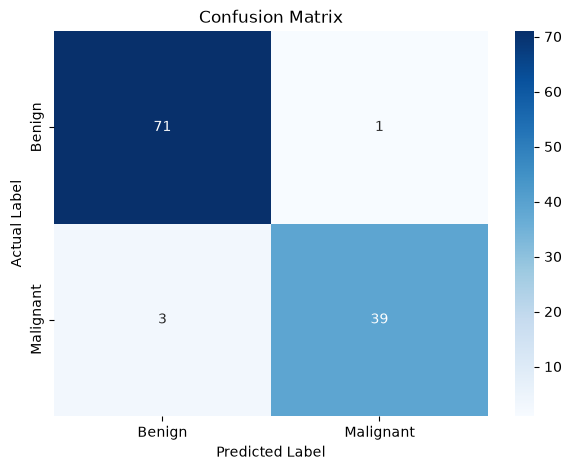

In [49]:
# Confusion Matrix

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Benign', 'Malignant'],
    yticklabels=['Benign', 'Malignant']
)

plt.title("Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.savefig("screenshots/confusion_matrix.png")
plt.show()


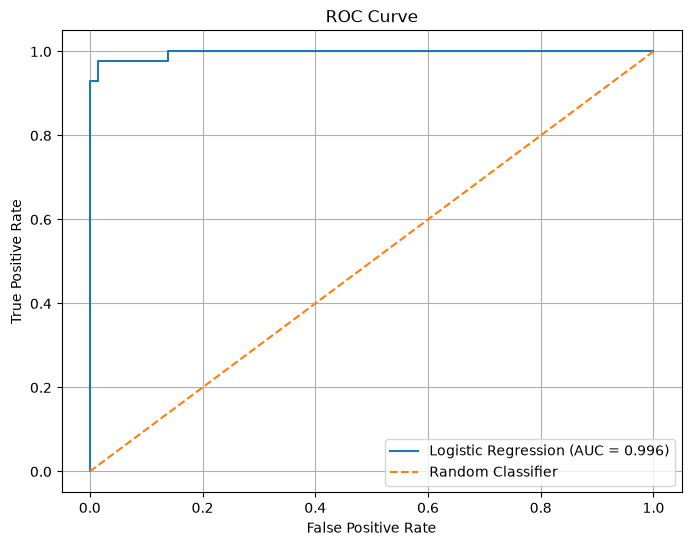

In [50]:
# ROC CURVE

fpr, tpr, thresholds = roc_curve(y_test, y_pred_proba)

plt.figure(figsize=(8, 6))

plt.plot(
    fpr,
    tpr,
    label=f"Logistic Regression (AUC = {roc_auc:.3f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--',
    label="Random Classifier"
)

plt.title("ROC Curve")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.grid()

plt.savefig("screenshots/roc_curve.png")
plt.show()


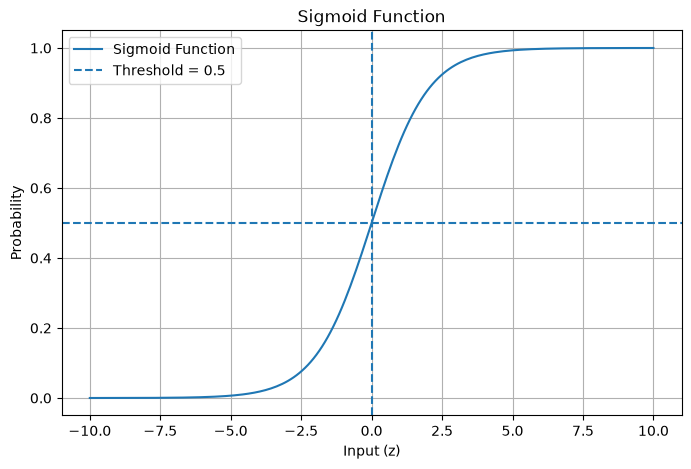

In [51]:
# Sigmoid Function

z = np.linspace(-10, 10, 200)

sigmoid = 1 / (1 + np.exp(-z))

plt.figure(figsize=(8, 5))

plt.plot(z, sigmoid, label="Sigmoid Function")

plt.axhline(y=0.5, linestyle='--', label="Threshold = 0.5")
plt.axvline(x=0, linestyle='--')

plt.title("Sigmoid Function")
plt.xlabel("Input (z)")
plt.ylabel("Probability")
plt.legend()
plt.grid()

plt.savefig("screenshots/sigmoid_function.png")
plt.show()


In [52]:
#THRESHOLD TUNING
# Define a new classification threshold

threshold = 0.3

# Generate predictions using the new threshold

y_pred_tuned = (y_pred_proba >= threshold).astype(int)

# Evaluate tuned predictions

print("\nTHRESHOLD TUNING RESULTS")
print("New Threshold:", threshold)

print("Accuracy:",
      round(accuracy_score(y_test, y_pred_tuned), 4))

print("Precision:",
      round(precision_score(y_test, y_pred_tuned), 4))

print("Recall:",
      round(recall_score(y_test, y_pred_tuned), 4))

print("F1 Score:",
      round(f1_score(y_test, y_pred_tuned), 4))



THRESHOLD TUNING RESULTS
New Threshold: 0.3
Accuracy: 0.9825
Precision: 0.9762
Recall: 0.9762
F1 Score: 0.9762


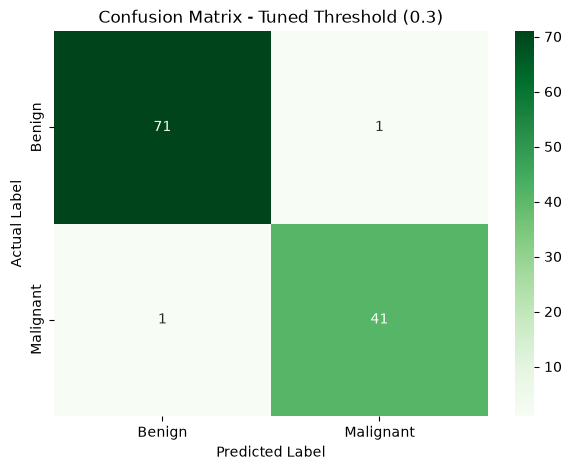

In [53]:
# Tuned Confusion Matrix

cm_tuned = confusion_matrix(y_test, y_pred_tuned)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_tuned,
    annot=True,
    fmt='d',
    cmap='Greens',
    xticklabels=['Benign', 'Malignant'],
    yticklabels=['Benign', 'Malignant']
)

plt.title("Confusion Matrix - Tuned Threshold (0.3)")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.savefig("screenshots/tuned_confusion_matrix.png")
plt.show()